In [1]:
# a = 4.6 + 6.9 + 7.24 + 11.22 + 14.5 + 5 + 48.5/2 +5.9 + 8.95 + 22.7 + 20.6
# print(a)

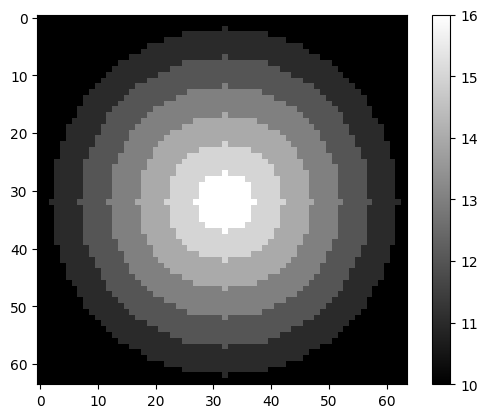

In [2]:
import numpy as np
import matplotlib.pyplot as plt

# create a 3D image containing n nested spheres: the first of radius a, the following of radius a - i*t
def create_spheres(n, a, t, shape, center=None):
    image = np.zeros(shape)
    if center is None:
        center = np.array(shape) // 2
    zz, yy, xx = np.ogrid[:shape[0], :shape[1], :shape[2]]
    dist2 = (zz - center[0]) ** 2 + (yy - center[1]) ** 2 + (xx - center[2]) ** 2
    for i in range(n):
        radius = a - i * t
        if radius <= 0:
            break
        image[dist2 <= radius ** 2] = i + 1  # +1 so the outer sphere differs from the background
    return image

spheres = create_spheres(n=6, a=30, t=5, shape=(64, 64, 64)) +10
# normalize the spheres to be in the range [0, 1]
# spheres = (spheres - spheres.min()) / (spheres.max() - spheres.min())

# show the spheres
plt.imshow(spheres[:, :, 32], cmap='gray')
plt.colorbar()
plt.show()


In [3]:
import nibabel as nib
import numpy as np

files = ["/home/agustin/phd/fast_nextbrain2/data/test/outputs/mrxfields/T1W/7T/001_GX/SuperSynth/segmentation.nii.gz"]
labels = np.unique(np.concatenate(
    [np.unique(nib.load(f).get_fdata().astype(int)) for f in files]))
# np.save("/home/agustin/phd/fast_nextbrain2/project/wp2/data/output/labels.npy", labels)
print("Labels:", labels)

# labels = np.unique(spheres)
# print("Labels:", labels)

Labels: [  0   2   3   4   5   7   8  10  11  12  13  14  15  16  17  18  24  26
  41  42  43  44  46  47  49  50  51  52  53  54  58  77  85 819 820 821
 822 843 844 865 866 869 870 902 915]


In [ ]:
# from sampling_scheme import ERCHierarchicalSampling
from sampling_scheme_v2 import GenericHierarchicalSampling as GHS

# scheme = ERCHierarchicalSampling(input_labels=labels, randomize_less=False)
# scheme = GHS.from_tissue_map(labels, {1:'WM', 2:'GM', 3:'CSF', 0:'BG'})  # e.g. your spheres
scheme = GHS(labels, config='freesurfer')  # e.g. your spheres



# One random "contrast": GM, WM, CSF, BG, DURA, SKULL, SCALP
# high_mus = np.random.uniform(10, 240, size=7)
# high_sigmas = np.random.uniform(1, 15, size=7)

high_mus = np.random.uniform(10, 240, size=4)
high_sigmas = np.random.uniform(1, 15, size=4)

print("Mus:", high_mus)
print("Sigmas:", high_sigmas)


mus, sigmas = scheme.compute_stats(high_mus, high_sigmas)


# print(scheme.get_class_weights())

[GENERATIVE MODEL]: 12 input labels not covered by the config (random policy): [819, 820, 821, 822, 843, 844, 865, 866, 869, 870, 902, 915]
[GENERATIVE MODEL]: MU/STD of ['BG'] are forced to 0
Mus: [ 51.22172255 235.40242909 182.58502106 178.80455426]
Sigmas: [ 5.88009976  7.24192712 10.9991823  14.51074333]


TypeError: SamplingScheme.get_class_weights() missing 1 required positional argument: 'subject_dict'

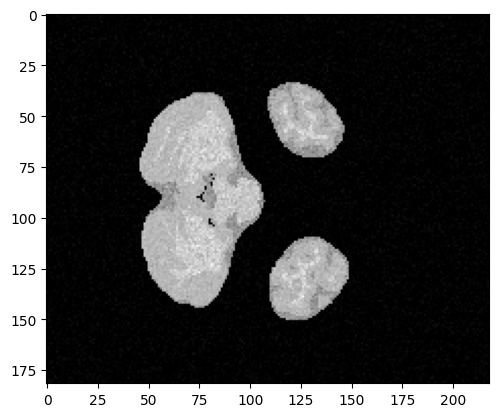

In [15]:
seg = nib.load(files[0])
lab = seg.get_fdata().astype(int)

# lab = spheres.astype(int)

idx = scheme.convert_labelmap(lab)   # raw IDs -> 0..N-1
image = mus[idx] + sigmas[idx] * np.random.randn(*idx.shape)
image = np.clip(image, 0, None)


# show the image
plt.imshow(image[:, :, 32], cmap='gray')

nib.save(nib.Nifti1Image(image.astype(np.float32), seg.affine), "/home/agustin/phd/fast_nextbrain2/project/wp2/data/output/synth.nii.gz")